# Chapter 4 — Building Models with Distance Metrics and Nearest Neighbors

**Nama:** Omar Al Farizy Hutagalung

**NIM:** 101032300034  

**Mata Kuliah:** Machine Learning  

**Tugas:** Tugas 2 — Code Reproduction & Theoretical Deep-Dive

---

## Objective

Chapter ini membahas distance metrics dan algoritma K-Nearest Neighbors (KNN).
Pembahasan meliputi Euclidean, Manhattan, Minkowski, Cosine, implementasi KNN,
evaluasi model, dan hyperparameter tuning.

## 1. Distance Metrics

Distance metric digunakan untuk mengukur tingkat kedekatan atau perbedaan
antara dua data point.

Beberapa distance metric yang digunakan dalam KNN:

- **Euclidean:** jarak garis lurus antar titik.
- **Manhattan:** jarak berdasarkan penjumlahan selisih absolut setiap fitur.
- **Minkowski:** bentuk umum yang mencakup Euclidean dan Manhattan.
- **Cosine:** mengukur kesamaan berdasarkan sudut antara dua vektor.

Pemilihan metric dapat memengaruhi hasil model. Scaling juga penting karena
metric seperti Euclidean sensitif terhadap perbedaan skala fitur.

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=3))
])

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9333333333333333


## 2. Understanding KNN

KNN melakukan klasifikasi berdasarkan label dari sejumlah tetangga terdekat.

Tahapan utamanya:

1. Menentukan jumlah tetangga `k`.
2. Menghitung jarak antara data baru dengan data training.
3. Memilih `k` data terdekat.
4. Menentukan kelas berdasarkan majority voting.

Nilai `k` yang terlalu kecil dapat membuat model sensitif terhadap noise,
sedangkan nilai `k` yang terlalu besar dapat menghilangkan pola lokal.

In [2]:
metrics = [
    "euclidean",
    "manhattan",
    "minkowski",
    "cosine"
]

results = {}

for metric in metrics:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=3,
            metric=metric
        ))
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results[metric] = accuracy_score(y_test, y_pred)

for metric, accuracy in results.items():
    print(f"{metric:10s}: {accuracy:.4f}")

euclidean : 0.9333
manhattan : 0.9667
minkowski : 0.9333
cosine    : 0.8333


### Analysis

Setiap distance metric dapat menghasilkan performa yang berbeda karena
mengukur kedekatan antar data dengan cara yang berbeda.

Metric terbaik tidak selalu sama untuk setiap dataset, sehingga beberapa metric
perlu dibandingkan menggunakan validation atau test performance.

In [3]:
from sklearn.model_selection import GridSearchCV

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors": range(1, 21),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan", "minkowski"]
}

grid_search = GridSearchCV(
    knn_model,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV accuracy:")
print(grid_search.best_score_)

Best parameters:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 17, 'knn__weights': 'distance'}

Best CV accuracy:
0.975


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



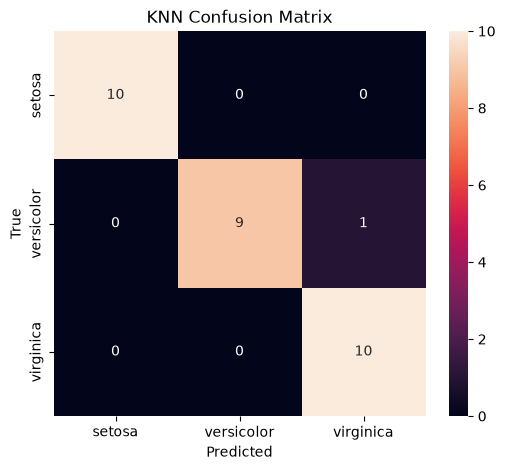

In [4]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("KNN Confusion Matrix")
plt.show()

## Conclusion

KNN melakukan klasifikasi berdasarkan kedekatan data menggunakan distance
metric tertentu.

Euclidean, Manhattan, Minkowski, dan Cosine dapat menghasilkan performa yang
berbeda. Oleh karena itu, distance metric perlu dipilih berdasarkan
karakteristik dataset dan dievaluasi secara empiris.

Hyperparameter seperti `n_neighbors`, `weights`, dan `metric` dapat
dioptimalkan menggunakan `GridSearchCV`.

Evaluasi menggunakan accuracy, confusion matrix, precision, recall, dan
F1-score membantu memahami performa model secara lebih lengkap.